# Домашнее задание

На языке ассемблера с использованием заданного механизма выделения памяти построить заданную структуру, реализуя в ней заданные функции (действия). Разработать программу на языке C, демонстрирующую использование данных функций на ассемблере. Построить Makefile, упрощающий процесс сборки исполняемых модулей.

In [ ]:
import random as rd

Variant = 14
rd.seed(Variant+1113332224456)

list_struct = ["Очередь", "Массив"]
get_memory = ["Куча", "Анонимное отображение"]
list_func_array = ["Создание массива заданного размера","Заполнение случайными числами", "Нахождение суммы элементов массива", "Подсчет количества четных чисел",
                   "Получение списка нечетных чисел", "Подсчет количества простых чисел", "Реверсирование элементов массива"]
list_func_quiuing = ["Добавление в конец","Удаление из начала", "Заполнение случайными числами",
                     "Подсчет количества четных чисел", "Получение списка нечетных чисел", "Подсчет количества простых чисел",
                    "Подсчет количества чисел, оканчивающихся на 1",
                     "Удаление всех четных чисел (прочитанное нечетное число добавляется обратно в конец)"]

name_struct = rd.sample(list_struct,1)
name_get_memory = rd.sample(get_memory,1)
if name_struct == ["Очередь"]:
    list_action =[list_func_quiuing[0], list_func_quiuing[1], list_func_quiuing[2]]+rd.sample(list_func_quiuing[3:],3)
if name_struct == ["Массив"]:
    list_action = [list_func_array[0], list_func_array[1]] + rd.sample(list_func_array[2:], 3)
print("Структура: ", name_struct)
print("Метод выделения памяти: ", name_get_memory)
print("Список функций (действий): ", list_action);


Структура:  ['Массив']
Метод выделения памяти:  ['Куча']
Список функций (действий):  ['Создание массива заданного размера', 'Заполнение случайными числами', 'Нахождение суммы элементов массива', 'Подсчет количества четных чисел', 'Реверсирование элементов массива']


In [ ]:
format elf64

public create_array
public generate_elems
public sum_array
public count_even
public reverse_array
public free_memory

section '.data' writable
    rnd db "/dev/random", 0

section '.bss' writable
    array_begin rq 1
    count rq 1

section '.text' executable
create_array: ; input rdi - размер массива, output rax - адрес массива
	mov [count], rdi
	;; Получаем начальное значение адреса кучи
	xor rdi,rdi
	mov rax, 12 ;brk
	syscall
	mov [array_begin], rax
	mov rdi, [array_begin]
	add rdi, [count]
	mov rax, 12 ; записываем новое значение адреса кучи
	syscall
	mov rax, [array_begin]
	ret

generate_elems:
    push rax
    push rcx
    push rdx
    push rsi
    push rdi

    mov rax, 2
    mov rdi, rnd
    mov rsi, 0o
    syscall
    cmp rax, 0
    jl .done ; не удалось открыть /dev/random
    mov rdi, rax ; rdi = дескриптор /dev/random

    mov rax, 0 ; читаем сразу count байт в массив
    mov rsi, [array_begin]
    mov rdx, [count]
    syscall

    mov rax, 3 ; close
    syscall

    .done:
    pop rdi
    pop rsi
    pop rdx
    pop rcx
    pop rax
    ret

sum_array: ; output rax - сумма элементов массива
    push rbx
    push rcx
    push rsi
    xor rbx, rbx
    xor rcx, rcx
    mov rsi, [array_begin]

    .loop:
        xor rax, rax
        mov al, byte [rsi+rcx]
        add rbx, rax
        inc rcx
        cmp rcx, [count]
        jb .loop

    mov rax, rbx
    pop rsi
    pop rcx
    pop rbx
    ret

count_even: ; output rax - количество четных чисел
    push rbx
    push rcx
    push rdx
    push rsi
    push rdi
    xor rbx, rbx
    xor rcx, rcx
    mov rsi, [array_begin] ; rsi = адрес начала массива в куче
    mov rdi, 2

    .loop:
        xor rax, rax
        mov al, byte [rsi+rcx]
        xor rdx, rdx
        div rdi ; rdx = остаток от деления на 2
        cmp rdx, 0
        jne .next
        inc rbx
    .next:
        inc rcx
        cmp rcx, [count]
        jb .loop

    mov rax, rbx
    pop rdi
    pop rsi
    pop rdx
    pop rcx
    pop rbx
    ret

reverse_array:
    push rax
    push rbx
    push rcx
    push rdx
    mov rax, [array_begin]
    xor rcx, rcx ; rcx - индекс с начала
    mov rdx, [count]
    dec rdx ; rdx - индекс с конца

    .loop:
        cmp rcx, rdx
        jge .done
        ; меняем местами элементы [rcx] и [rdx]
        mov bl, [rax+rcx]
        mov bh, [rax+rdx]
        mov [rax+rcx], bh
        mov [rax+rdx], bl
        inc rcx
        dec rdx
        jmp .loop

    .done:
    pop rdx
    pop rcx
    pop rbx
    pop rax
    ret

free_memory:
	mov rdi, [array_begin] ; сбрасываем адрес кучи до исходного
	mov rax, 12
	syscall
	ret


In [ ]:
#include <stdio.h>
#include <stdlib.h> // для atol

unsigned char* create_array(size_t size); // rdi - размер, rax - адрес массива
void generate_elems(void);
long sum_array(void); // rax - сумма
long count_even(void); // rax - количество четных
void reverse_array(void);
void free_memory(void);

void print_array(unsigned char *a, size_t n)
{
    for (int i = 0; i < n; i++) {
        printf("%d ", a[i]);
    }
    printf("\n");
}

int main(int argc, char **argv)
{
    if (argc != 2) {
        printf("error while reading size\n");
        return 1;
    }
    long n = atol(argv[1]);
    if (n <= 0 || n > 100) {
        printf("size must be from 1 to 100\n");
        return 1;
    }

    printf("size = %ld\n", n); // буфер stdout выделяется в куче раньше массива

    unsigned char *a = create_array(n); // каждый элемент занимает 1 байт
    generate_elems();
    print_array(a, n);

    // считаем то же самое на C для сравнения
    long sum = 0, even = 0;
    unsigned char copy[100];
    for (int i = 0; i < n; i++) {
        sum += a[i];
        if (a[i] % 2 == 0) {
            even++;
        }
        copy[i] = a[i];
    }

    long asm_sum = sum_array();
    long asm_even = count_even();

    printf("sum:  asm = %ld, C = %ld\n", asm_sum, sum);
    printf("even: asm = %ld, C = %ld\n", asm_even, even);

    reverse_array();
    printf("reversed:\n");
    print_array(a, n);

    int ok = 1;
    for (int i = 0; i < n; i++) {
        if (a[i] != copy[n - 1 - i]) {
            ok = 0;
        }
    }

    if (ok) {
        printf("reverse OK\n");
    } else {
        printf("reverse FAIL\n");
    }

    free_memory();
    return 0;
}


In [ ]:
homework_asm: homework.asm
	fasm homework.asm

main_c: main.c
	gcc -c main.c -o main.o

build: homework_asm main_c
	gcc main.o homework.o -o homework

run: build homework
	./homework $(var)

clean:
	rm -f *.o


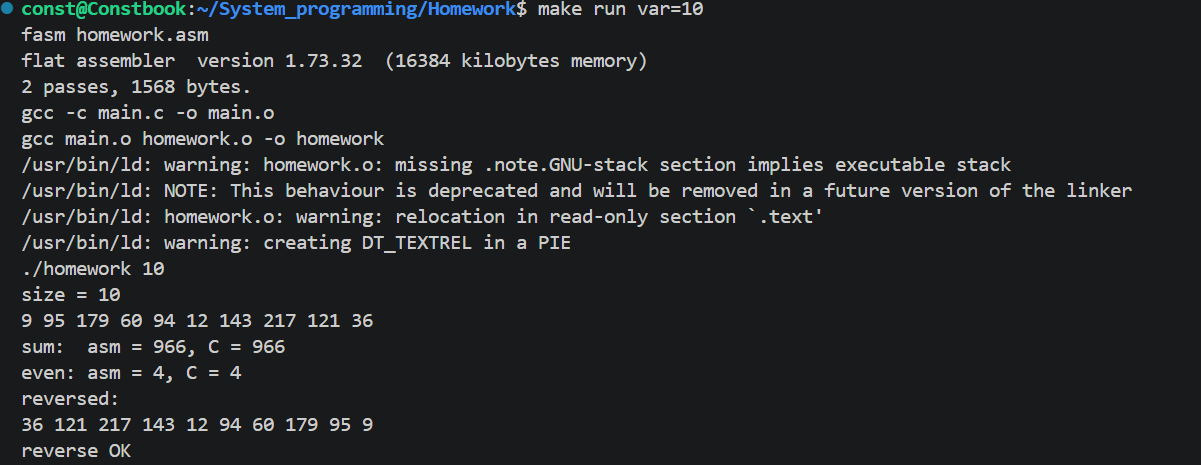
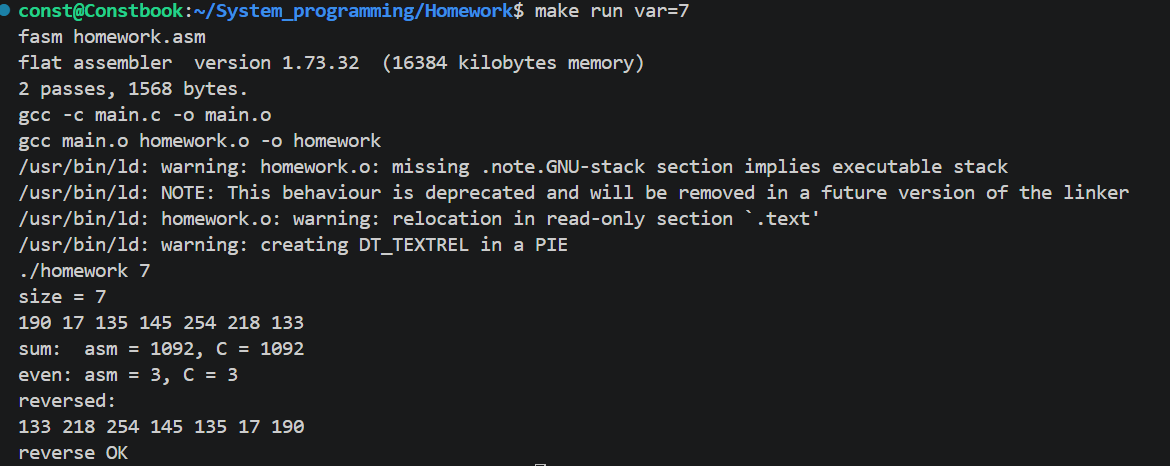